<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# A closer training fit can hide larger unseen-row errors

Train a regression tree through SQL, score both training and held-out samples, and compare their error distributions. Then allow a deeper tree while keeping the data, features and random state fixed. The question is whether fitting the training sample more closely improves predictions for rows excluded from fitting.

**Every input is synthetic.** There are 80 training and 120 held-out samples drawn independently from the same stated distribution: x is uniform on [−3,3], the conditional mean is `sin(1.5*x) + 0.2*x`, and independent Gaussian noise has standard deviation 0.35. Both x and the target are dimensionless. Fixed labels and a seeded generator are bundled; there are no observed subjects or event timestamps.

## Choose tree capacity

`MAX_DEPTH` accepts an integer from **1 to 16**, default **3**. The focused experiment uses **12**. Restart and run all after editing. The training partition and one feature x stay fixed; neither identifiers, partition labels, held-out targets nor the known synthetic mean enter the fitted feature matrix. This pair of demonstrations is not a hyperparameter search, and viewing held-out results does not make them an untouched basis for later model selection.

In [1]:
MAX_DEPTH = 3  # Maximum tree depth; experiment: 12

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from notebook_support import NotebookRegistry, finish, theme

assert type(MAX_DEPTH) is int and 1 <= MAX_DEPTH <= 16
manifest = json.loads(Path("fixtures/provenance.json").read_text())
assert hashlib.sha256((Path("fixtures") / manifest["file"]).read_bytes()).hexdigest() == manifest["sha256"]
registry = NotebookRegistry()
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-scikit-learn/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-scikit-learn/notebooks/pyproject.toml.

## Fit once, using only the training matrix

The literal Git command pins the worker and its tested numerical/serialization libraries. The notebook creates a fresh temporary model registry through the supported `SKLEARN_MODELS_DIR` setting, so the named model is local to this run. Cleanup removes it after closing the worker.

The fit returns a serialized model BLOB and metadata and stores the named model in that disposable registry. The call is materialized once: captured SELECT output is taken from the local table afterward, so display cannot retrain it. The visible projection passes **only x and the training target**. Model metadata must confirm one feature and the expected training row count.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'sklearn' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with scikit-learn==1.9.0 --with skops==0.14.0 --with numpy==2.5.0 --with scipy==1.18.0 --from git+https://github.com/Query-farm/vgi-scikit-learn@9ebed7eb059fd80aa7306b9e87e23f6958491334 vgi-sklearn');
CREATE TABLE samples AS SELECT * FROM read_csv_auto('fixtures/synthetic_regression.csv');
CREATE TABLE fitted AS SELECT * FROM sklearn.estimators.fit_decision_tree_regressor(
 (SELECT x,target FROM samples WHERE split='train'),target:='target',
 model_name:='notebook_tree',max_depth:={{MAX_DEPTH}},random_state:=17);
CREATE TABLE registry_entries AS SELECT * FROM sklearn.models.list_models();

,Count


In [4]:
%%sql fit_info <<
SELECT * EXCLUDE(model) FROM fitted;

In [5]:
display(fit_info)

,model_name,estimator,task,n_samples,n_features,n_classes,train_score,features
0,notebook_tree,decision_tree_regressor,regression,80,1,<NA>,0.842449,[x]


## Score rows and a display grid through the stored model

Prediction receives each identifier and x, then returns the identifier with its prediction. SQL joins the targets and partition labels back **after** scoring. The same stored model handles training rows, held-out rows and a dense x grid. Its piecewise-constant curve is compared with the known conditional mean, which is available only because these data were generated for this example.

The grid is for visualization, not extra training data or an empirical test population. All fitting, prediction and worker metrics go through the real VGI worker; Python never fits or loads a scikit-learn estimator.

In [6]:
%%sql
CREATE TABLE predictions AS SELECT * FROM sklearn.models.predict(
 (SELECT sample_id,x FROM samples),model_name:='notebook_tree',id:='sample_id');
CREATE TABLE evaluated AS SELECT s.*,p.prediction,p.prediction-s.target AS residual,
 abs(p.prediction-s.target) AS absolute_error
FROM samples s JOIN predictions p USING(sample_id);
CREATE TABLE grid AS SELECT i AS grid_id,i/100.0 AS x FROM range(-300,301) AS t(i);
CREATE TABLE grid_predictions AS SELECT * FROM sklearn.models.predict(
 (SELECT grid_id,x FROM grid),model_name:='notebook_tree',id:='grid_id');
CREATE TABLE grid_results AS SELECT g.*,p.prediction,sin(1.5*g.x)+0.2*g.x AS conditional_mean
FROM grid g JOIN grid_predictions p USING(grid_id);

,Count


In [7]:
%%sql observations <<
SELECT sample_id,split,x,target,prediction,residual,absolute_error FROM evaluated ORDER BY sample_id;

In [8]:
%%sql curve <<
SELECT * FROM grid_results ORDER BY x;

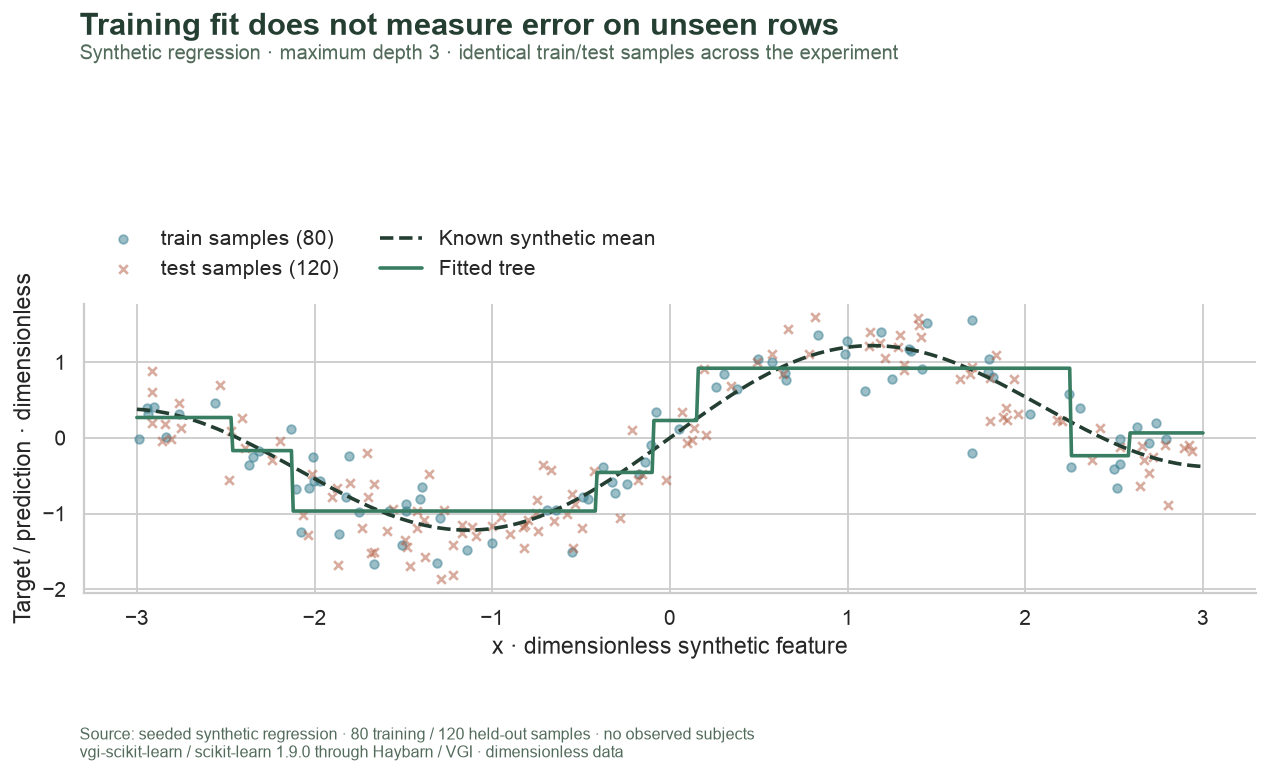

In [9]:
fig, ax = plt.subplots(figsize=(10.5, 6))
for split, color, marker in [("train", "#397f91", "o"), ("test", "#b25b3f", "x")]:
    frame = observations.loc[observations.split == split]
    ax.scatter(
        frame.x, frame.target, s=23, alpha=0.5, color=color, marker=marker, label=f"{split} samples ({len(frame)})"
    )
ax.plot(curve.x, curve.conditional_mean, "--", color="#243e32", linewidth=2, label="Known synthetic mean")
ax.plot(curve.x, curve.prediction, color="#397d62", linewidth=2, label="Fitted tree")
ax.set(xlabel="x · dimensionless synthetic feature", ylabel="Target / prediction · dimensionless")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2, frameon=False)
finish(
    fig,
    f"fit-depth-{MAX_DEPTH}",
    "Training fit does not measure error on unseen rows",
    f"Synthetic regression · maximum depth {MAX_DEPTH} · identical train/test samples across the experiment",
)

## Reconcile worker metrics with visible SQL arithmetic

The worker computes RMSE, MAE and R² separately for the two partitions. SQL independently computes squared and absolute residual summaries as a numerical cross-check. RMSE and MAE have the same dimensionless target units; R² is a relative fit score and can be negative. The training score reported at fit time should agree with R² recomputed from training predictions.

A lower training error alone says little about unseen rows. Compare the held-out error and its distribution without choosing a model based on a predeclared preferred result.

In [10]:
%%sql
CREATE TABLE metrics AS SELECT split,count(*) AS row_count,
 sklearn.metrics.root_mean_squared_error(target,prediction) AS rmse,
 sklearn.metrics.mean_absolute_error(target,prediction) AS mae,
 sklearn.metrics.r2_score(target,prediction) AS r2,
 sqrt(avg(residual*residual)) AS sql_rmse,avg(absolute_error) AS sql_mae,
 quantile_cont(absolute_error,0.5) AS median_absolute_error,
 quantile_cont(absolute_error,0.9) AS p90_absolute_error
FROM evaluated GROUP BY split;
CREATE TABLE error_cdf AS SELECT split,absolute_error,
 cume_dist() OVER(PARTITION BY split ORDER BY absolute_error) AS fraction_at_or_below
FROM evaluated;

,Count


In [11]:
%%sql scores <<
SELECT * FROM metrics ORDER BY split;

In [12]:
%%sql distribution <<
SELECT * FROM error_cdf ORDER BY split,absolute_error,fraction_at_or_below;

,split,row_count,rmse,mae,r2,sql_rmse,sql_mae,median_absolute_error,p90_absolute_error
0,test,120,0.407589,0.329516,0.797969,0.407589,0.329516,0.272642,0.688521
1,train,80,0.330424,0.251367,0.842449,0.330424,0.251367,0.185323,0.593291


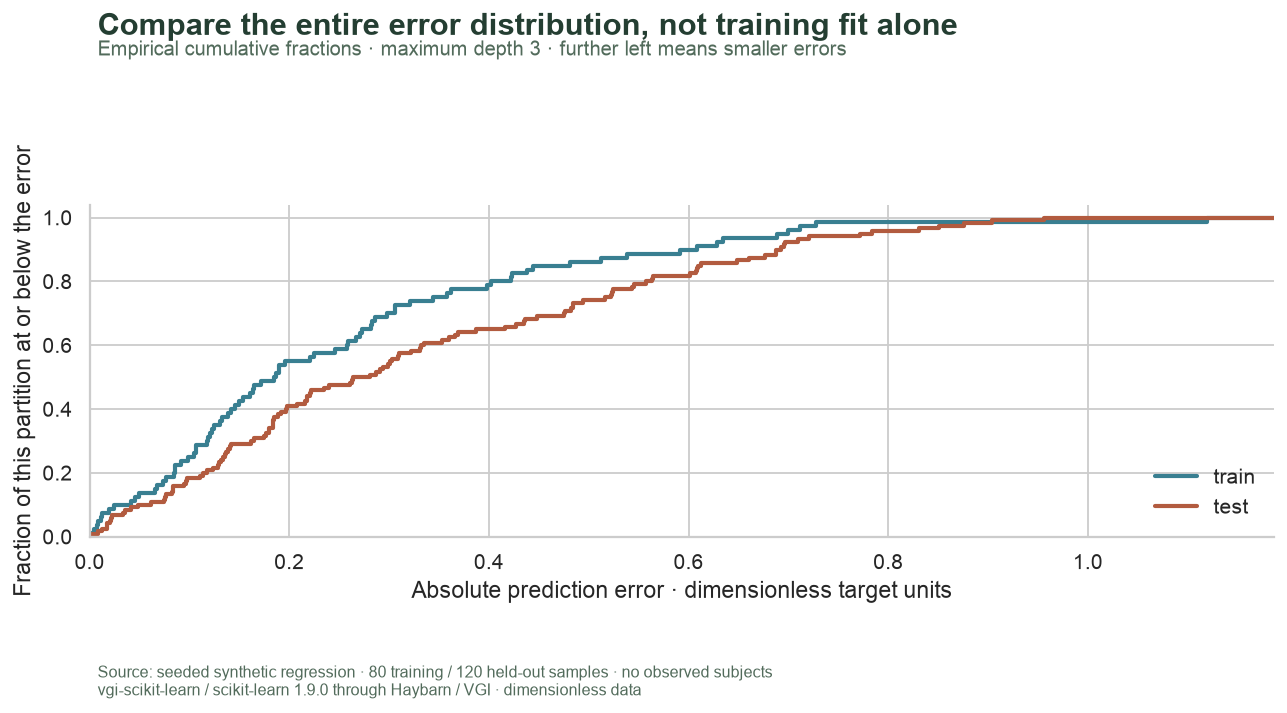

In [13]:
display(scores)
fig, ax = plt.subplots(figsize=(10.5, 5.5))
right = max(float(distribution.absolute_error.max()) * 1.06, 0.01)
for split, color in [("train", "#397f91"), ("test", "#b25b3f")]:
    frame = distribution.loc[distribution.split == split]
    ax.step(
        np.r_[0, frame.absolute_error, right],
        np.r_[0, frame.fraction_at_or_below, 1],
        where="post",
        color=color,
        linewidth=2.3,
        label=split,
    )
ax.set(
    xlabel="Absolute prediction error · dimensionless target units",
    ylabel="Fraction of this partition at or below the error",
    xlim=(0, right),
    ylim=(0, 1.04),
)
ax.legend(loc="lower right", frameon=False)
finish(
    fig,
    f"errors-depth-{MAX_DEPTH}",
    "Compare the entire error distribution, not training fit alone",
    f"Empirical cumulative fractions · maximum depth {MAX_DEPTH} · further left means smaller errors",
)

In [14]:
train = scores.loc[scores.split == "train"].iloc[0]
test = scores.loc[scores.split == "test"].iloc[0]
display(
    Markdown(
        f"At maximum depth **{MAX_DEPTH}**, training RMSE is **{train.rmse:.4f}** and held-out RMSE is "
        f"**{test.rmse:.4f}**, a held-out-minus-training gap of **{test.rmse - train.rmse:+.4f}** target units. "
        f"The held-out median absolute error is **{test.median_absolute_error:.4f}**; its 90th percentile is "
        f"**{test.p90_absolute_error:.4f}**. Training R² is **{train.r2:.4f}**, compared with **{test.r2:.4f}** "
        "on held-out rows. This fixed synthetic sample illustrates the distinction; "
        "it is not a population accuracy guarantee."
    )
)

At maximum depth **3**, training RMSE is **0.3304** and held-out RMSE is **0.4076**, a held-out-minus-training gap of **+0.0772** target units. The held-out median absolute error is **0.2726**; its 90th percentile is **0.6885**. Training R² is **0.8424**, compared with **0.7980** on held-out rows. This fixed synthetic sample illustrates the distinction; it is not a population accuracy guarantee.

## Check the data boundary and numerical relationships

Checks verify row identity, fit metadata, one prediction per row, finite values, grid coverage, metric reconciliation and the empirical CDF. They deliberately do not require a particular depth to improve held-out error. Model registry checks confirm this run created just the intended model in its isolated directory.

In [15]:
%%sql checks <<
SELECT 'sample identifiers are unique' AS check_name,
 (SELECT count(*)=count(DISTINCT sample_id) FROM samples) AS passed
UNION ALL SELECT 'training and test rows are nonempty and partitioned',
 (SELECT count(DISTINCT split)=2 AND bool_and(split IN ('train','test')) FROM samples)
UNION ALL SELECT 'fit row count includes training only',
 (SELECT n_samples=(SELECT count(*) FROM samples WHERE split='train') FROM fitted)
UNION ALL SELECT 'one feature is fitted and target/id are excluded',
 (SELECT n_features=1 AND features=['x'] FROM fitted)
UNION ALL SELECT 'one intended model is in the temporary registry',
 (SELECT count(*)=1 AND bool_and(model_name='notebook_tree') FROM registry_entries)
UNION ALL SELECT 'predictions preserve every identifier exactly once',
 (SELECT count(*)=count(DISTINCT sample_id) AND count(*)=(SELECT count(*) FROM samples) FROM predictions)
 AND NOT EXISTS(SELECT sample_id FROM samples EXCEPT SELECT sample_id FROM predictions)
UNION ALL SELECT 'predictions and targets are finite',
 (SELECT bool_and(isfinite(target) AND isfinite(prediction)) FROM evaluated)
UNION ALL SELECT 'grid predictions cover all grid rows uniquely',
 (SELECT count(*)=count(DISTINCT grid_id) AND count(*)=(SELECT count(*) FROM grid) FROM grid_results)
UNION ALL SELECT 'worker RMSE agrees with SQL',(SELECT bool_and(abs(rmse-sql_rmse)<1e-10) FROM metrics)
UNION ALL SELECT 'worker MAE agrees with SQL',(SELECT bool_and(abs(mae-sql_mae)<1e-10) FROM metrics)
UNION ALL SELECT 'MAE is bounded by RMSE',(SELECT bool_and(mae<=rmse+1e-10 AND mae>=0) FROM metrics)
UNION ALL SELECT 'fit score agrees with recomputed training R2',
 (SELECT abs(f.train_score-m.r2)<1e-10 FROM fitted f CROSS JOIN metrics m WHERE m.split='train')
UNION ALL SELECT 'empirical CDF fractions are valid and end at one',
 (SELECT bool_and(lo>0 AND hi=1) FROM(SELECT split,min(fraction_at_or_below) lo,
 max(fraction_at_or_below) hi FROM error_cdf GROUP BY split));

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
assert int(train.row_count) == manifest["train_rows"] and int(test.row_count) == manifest["test_rows"]
display(Markdown(f"**{len(checks)} SQL checks passed**, and partition sizes agree with the fixture provenance."))

,check_name,passed
0,sample identifiers are unique,True
1,training and test rows are nonempty and partit...,True
2,fit row count includes training only,True
3,one feature is fitted and target/id are excluded,True
4,one intended model is in the temporary registry,True
5,predictions preserve every identifier exactly ...,True
6,predictions and targets are finite,True
7,grid predictions cover all grid rows uniquely,True
8,worker RMSE agrees with SQL,True
9,worker MAE agrees with SQL,True


**13 SQL checks passed**, and partition sizes agree with the fixture provenance.

## Focused experiment: allow a deeper tree

Change only **`MAX_DEPTH` from 3 to 12**, restart and run all. Predict a more intricate fitted curve and lower training error. Check whether held-out RMSE and the orange error distribution improve by the same amount, or deteriorate. The data, split, feature projection and model seed stay fixed.

Compare both plots and the result-derived training/held-out gap. A deeper tree can fit noise in this finite sample; this is not a rule that shallow trees always generalize better. An actual model-selection workflow needs validation separate from a final untouched test set. Restore **3** for the saved baseline; the README command writes the experiment separately.

In [17]:
connection.close()
registry.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>